<a href="https://colab.research.google.com/github/apkh1116/strong-kheer-191531/blob/apkh/%EC%9E%A5%EA%B7%9C%ED%98%84_1_%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%A0%84%EC%B2%98%EB%A6%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#[1단계] 데이터 수집하기 (Data Collection)

In [ ]:
#1-1.데이터 불러오기
import pandas as pd
df = pd.read_csv('penguins_size.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


#[2단계] 데이터 살펴보기

In [ ]:
#2-1.데이터의 속성과 유형 살펴보기(info)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   culmen_length_mm   333 non-null    float64
 3   culmen_depth_mm    333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.8+ KB


In [ ]:
#2-2.데이터 통곗값 요약(describe)
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


<Axes: xlabel='sex', ylabel='count'>

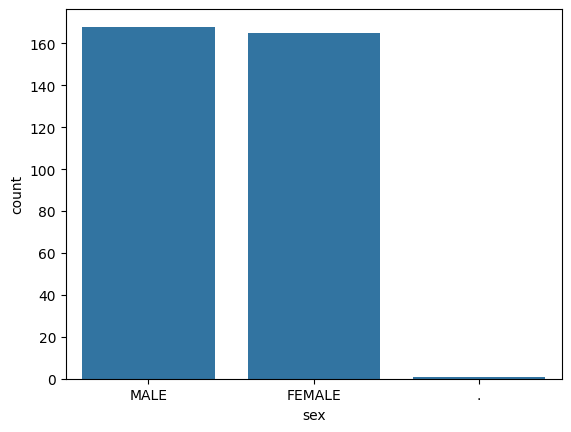

In [ ]:
#2-3.데이터 시각화
import seaborn as sns
sns.countplot(x=df['sex'])

#[3단계] 데이터 전처리하기 (Data Preprocessing)

In [ ]:
#3-1.결측치 처리하기
#결측치 수 확인
df.isnull().sum()

,0
species,0
island,0
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


In [ ]:
#결측치 행 삭제
df=df.dropna(axis=0)
df.shape

(334, 7)

<Axes: xlabel='body_mass_g'>

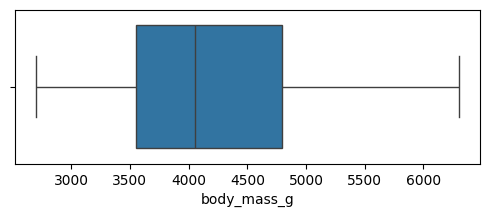

In [ ]:
#3-2.이상치 확인하기
#상자그림 이용
import matplotlib.pyplot as plt
plt.figure(figsize=(6,2))
sns.boxplot(data=df, x='body_mass_g')

In [ ]:
#고유한 값의 종류 출력
df['species'].unique()
df['sex'].unique()

array(['MALE', 'FEMALE', '.'], dtype=object)

In [ ]:
#이상치가 있는 있는 행 확인
df[df['sex']=='.']

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,.


In [ ]:
#확인된 행 삭제
df.drop(336,axis=0, inplace=True)

/tmp/ipykernel_2437/704997602.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(336,axis=0, inplace=True)


In [ ]:
#삭제 여부 확인
df.shape

(333, 7)

In [ ]:
#3-3.정규화(최소-최대 정규화)
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
df[['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g']]=scaler.fit_transform(df[['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g']])
df.head()

/tmp/ipykernel_2437/4203529333.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g']]=scaler.fit_transform(df[['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g']])


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,0.254545,0.666667,0.152542,0.291667,MALE
1,Adelie,Torgersen,0.269091,0.511905,0.237288,0.305556,FEMALE
2,Adelie,Torgersen,0.298182,0.583333,0.389831,0.152778,FEMALE
4,Adelie,Torgersen,0.167273,0.738095,0.355932,0.208333,FEMALE
5,Adelie,Torgersen,0.261818,0.892857,0.305085,0.263889,MALE


#[4단계] 핵심 속성 추출하기

<Axes: xlabel='culmen_length_mm', ylabel='culmen_depth_mm'>

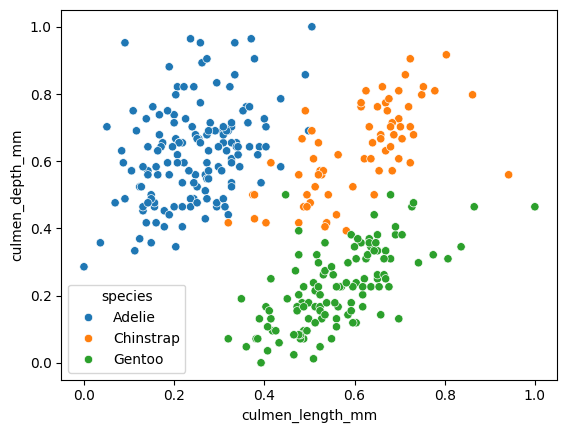

In [ ]:
#4-1.산점도 이용(부리길이, 부리깊이)
import seaborn as sns
sns.scatterplot(x='culmen_length_mm',y='culmen_depth_mm', data=df, hue='species')

<Axes: xlabel='culmen_length_mm', ylabel='flipper_length_mm'>

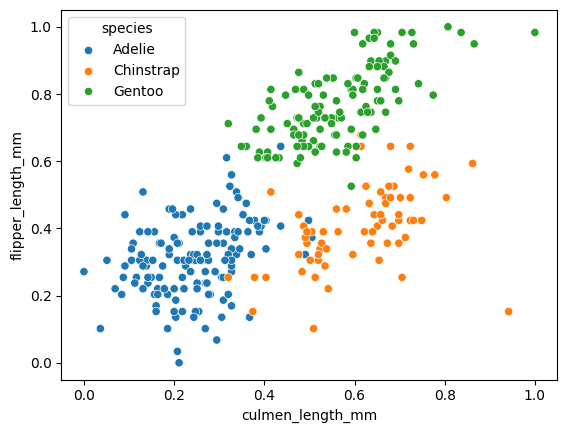

In [ ]:
#4-2.산점도 이용(부리깊이, 날개 길이)
import seaborn as sns
sns.scatterplot(x='culmen_length_mm',y='flipper_length_mm', data=df, hue='species')

<Axes: xlabel='culmen_length_mm', ylabel='body_mass_g'>

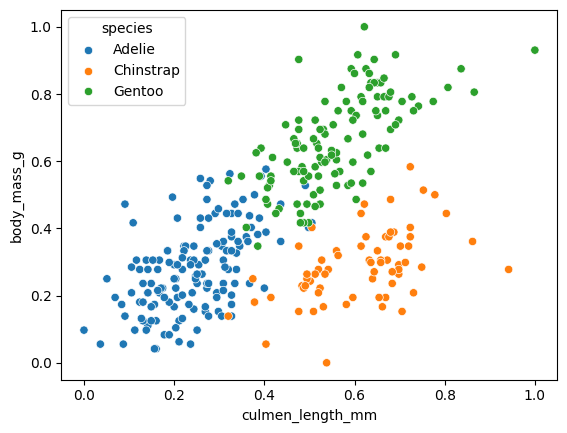

In [ ]:
#4-3.산점도, 회귀선(부리길이, 체질량)
import seaborn as sns
sns.scatterplot(x='culmen_length_mm',y='body_mass_g', data=df, hue='species')

<Axes: >

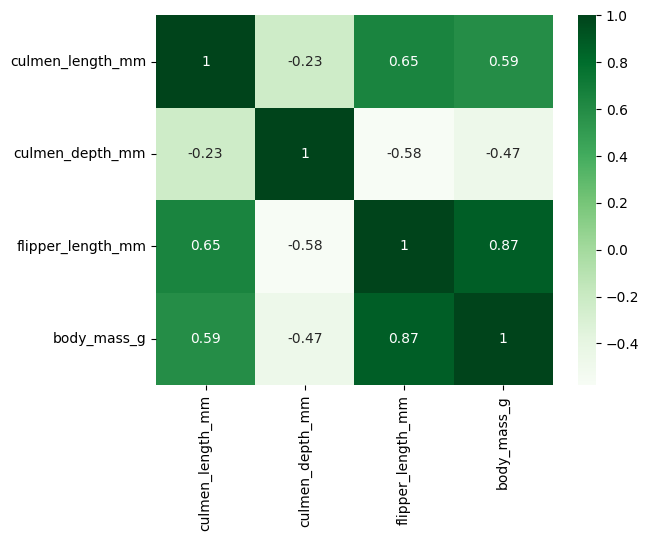

In [ ]:
#4-4.히트맵으로 속성 간의 상관관계 시각화
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Greens')